# ECG Arrhythmia Classification with CWT Scalograms and a CNN (V4)

**Curated publication copy of the original V4 Colab notebooks.**

> **How to read this notebook**
> - Every **code cell** is copied *verbatim*, including its **saved output**, from the original notebooks
>   `v4_Preprocessing.ipynb` and `v4_2_Model.ipynb` (Google Colab, April 2026). The cell metadata field
>   `provenance` records the source notebook and cell number.
> - **Markdown cells** (like this one) were added afterwards to explain the code. They are documentation, not original output.
> - The notebook was **not re-executed** for publication. All outputs are **historical**.
> - The code expects the original Google Drive layout and the raw PhysioNet records. It cannot run as is (see *Inputs*).
> - Exploratory dead ends were removed, along with several cells that drew **synthetic or hand-typed figures**
>   (see *Excluded material*). Nothing was added to or altered in any output.

## Pipeline overview

```
WFDB record (360 Hz, lead 0) + reference beat annotations (.atr)
  └─ for every annotation i (except first/last): segment = signal[R_i - 150 : R_i + 150]   (300 samples)
       └─ CWT, Mexican-hat wavelet, scales 1..128           -> |coefficients|  (128 x 300)
            └─ cv2.resize to 256 x 256 -> min-max to 0..255 -> uint8 grayscale scalogram
                 └─ stored with the raw annotation symbol in HDF5 batches of 1,000 (train/val by record)
AAMI mapping of symbols -> 5 classes (N, S, V, F, Q); non-beat symbols dropped
Balanced set: first 20,000 N beats + all S, V, F, Q beats  -> 39,982 images (v4.2_balanced.h5)
CNN input: grayscale image repeated to 3 channels, / 255  -> (256, 256, 3)
```

There is **no band-pass filtering, baseline-wander removal or automatic R-peak detection**. Beats are cut
at the database's reference annotation positions.

## Inputs and dependencies

**Historical environment (from the saved Colab outputs):** Python 3.12, TensorFlow 2.20.0, Keras 3.13.2,
NumPy 2.0.2, wfdb 4.3.1, plus PyWavelets, OpenCV, h5py and scikit-learn (versions not recorded).
Mixed precision (`mixed_float16`) was used on a Colab GPU.

**Expected files (not distributed with this repository):**

| Path used in the code (Google Drive) | Content |
|---|---|
| `Final_Year_Project/datasets/raw/MIT-BIH/` | 48 MIT-BIH Arrhythmia Database records (`.dat`, `.hea`, `.atr`) |
| `Final_Year_Project/datasets/raw/INCART/` | 27 MIT-BIH ST Change Database records, 301–327 (see the note below) |
| `Final_Year_Project/datasets/v4_database/` | Output of step 1: 150 `train_v4_batch_N.h5` and 35 `val_v4_batch_N.h5` |
| `Final_Year_Project/datasets/v4.2_cleaned/v4.2_balanced.h5` | Output of step 3 (39,982 × 256 × 256 uint8) |
| `Final_Year_Project/models/godzilla_v4_fast_mode.keras` | Output of step 4. The deployed `models/v4_custom_fast_mode.keras` is byte-identical (SHA-256) |

**Dataset naming caveat.** The original code calls the second folder "INCART", but it holds **MIT-BIH ST Change
Database** (`stdb`) records 301–327. All 27 header files are byte-identical to the official `stdb` v1.0.0 headers.
The St Petersburg INCART database (75 × 30-minute, 12-lead, 257 Hz records) was downloaded in an earlier version
but was **not** used by V4.

Data sources (PhysioNet, ODC Attribution License v1.0): MIT-BIH Arrhythmia Database (`mitdb`,
<https://doi.org/10.13026/C2F305>) and MIT-BIH ST Change Database (`stdb`, <https://doi.org/10.13026/C2ZW2H>).
This notebook's outputs contain information from both databases.

## Step 1. Beat segmentation and CWT scalograms
*Source: `v4_Preprocessing.ipynb`, cell 21.*

- Records are split **by record** into train/validation with `train_test_split(all_recs, test_size=0.2, random_state=42)`
  (60 / 15 records). The batch files keep this separation.
- The loop has resume logic because the original run crashed several times. The saved output below is from
  the final resume run, which only completed the remaining validation batches.
- Each batch is written only when 1,000 images have accumulated, so the final partial batch of each split
  (fewer than 1,000 beats) was never saved.
- The demo application (`app/inference.py`) reproduces the CWT lines of this cell exactly. Regenerating
  13,000 beats from the raw records reproduced the stored images with identical annotation symbols. Pixels
  matched exactly except, in about 20% of images, the single brightest pixel (254 vs 255). That comes from float
  truncation in `astype('uint8')` and differs between library versions. It did not change any of 1,000 tested
  predictions (`scripts/verify_preprocessing_parity.py`).

In [ ]:
import os
import h5py
import wfdb
import pywt
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from google.colab import drive
from datetime import datetime

# ==========================================
# 1. INITIALIZATION & MOUNTING
# ==========================================
drive.mount('/content/drive', force_remount=True)

BASE_DIR = '/content/drive/MyDrive/Final_Year_Project/'
RAW_DIR = os.path.join(BASE_DIR, 'datasets/raw/')
DB_DIR = os.path.join(BASE_DIR, 'datasets/v4_database/')
LOG_PATH = os.path.join(BASE_DIR, 'results/v4_development_log.txt')

os.makedirs(DB_DIR, exist_ok=True)

# ==========================================
# 2. DATASET MAPPING (MIT-BIH + INCART)
# ==========================================
def get_recs(path):
    if os.path.exists(path):
        return sorted(list(set([f.split('.')[0] for f in os.listdir(path) if f.endswith('.dat')])))
    return []

mit_recs = get_recs(os.path.join(RAW_DIR, 'MIT-BIH'))
incart_recs = get_recs(os.path.join(RAW_DIR, 'INCART'))
all_recs = mit_recs + incart_recs

# 80/20 Patient-Wise Split (Must match original random_state=42)
train_recs, val_recs = train_test_split(all_recs, test_size=0.2, random_state=42)

# ==========================================
# 3. RESUME LOGIC (Smart Check)
# ==========================================
def run_generator(record_list, split_name):
    existing_batches = sorted([f for f in os.listdir(DB_DIR) if f"{split_name}_v4_batch" in f])
    start_batch = len(existing_batches)
    total_to_skip = start_batch * 1000

    print(f"📦 {split_name.upper()} SET: Found {start_batch} existing batches. Skipping {total_to_skip} images...")

    images, labels = [], []
    batch_count = start_batch
    current_idx = 0

    for rec in record_list:
        folder = 'MIT-BIH' if rec in mit_recs else 'INCART'
        path = os.path.join(RAW_DIR, folder, rec)

        try:
            record = wfdb.rdrecord(path)
            ann = wfdb.rdann(path, 'atr')
            signal = record.p_signal[:, 0]

            for i in range(1, len(ann.sample) - 1):
                if current_idx < total_to_skip:
                    current_idx += 1
                    continue

                start, end = ann.sample[i]-150, ann.sample[i]+150
                if start < 0 or end > len(signal): continue

                # CWT 256x256 Mexican Hat
                scales = np.arange(1, 129)
                coef, _ = pywt.cwt(signal[start:end], scales, 'mexh')
                rescaled = cv2.resize(np.abs(coef), (256, 256))
                norm_img = cv2.normalize(rescaled, None, 0, 255, cv2.NORM_MINMAX).astype('uint8')

                images.append(norm_img)
                labels.append(ann.symbol[i].encode('utf-8'))

                if len(images) >= 1000:
                    save_path = f"{DB_DIR}{split_name}_v4_batch_{batch_count}.h5"
                    with h5py.File(save_path, 'w') as hf:
                        hf.create_dataset('images', data=np.array(images), compression="gzip")
                        hf.create_dataset('labels', data=np.array(labels))
                    print(f"✔️ Saved {split_name} Batch {batch_count}")
                    images, labels = [], []
                    batch_count += 1
                current_idx += 1
        except: continue

# ==========================================
# 4. EXECUTION
# ==========================================
run_generator(train_recs, 'train')
run_generator(val_recs, 'val')

print("\n🏁 GODZILLA V4 PREPROCESSING: 100% COMPLETE")
print(f"📂 Location: {DB_DIR}")

Mounted at /content/drive
📦 TRAIN SET: Found 150 existing batches. Skipping 150000 images...
📦 VAL SET: Found 26 existing batches. Skipping 26000 images...
✔️ Saved val Batch 26
✔️ Saved val Batch 27
✔️ Saved val Batch 28
✔️ Saved val Batch 29
✔️ Saved val Batch 30
✔️ Saved val Batch 31
✔️ Saved val Batch 32
✔️ Saved val Batch 33
✔️ Saved val Batch 34

🏁 GODZILLA V4 PREPROCESSING: 100% COMPLETE
📂 Location: /content/drive/MyDrive/Final_Year_Project/datasets/v4_database/


## Step 2. AAMI class mapping
*Source: `v4_2_Model.ipynb`, cell 3.* Raw annotation symbols are grouped into the five AAMI classes. Symbols
outside the mapping (rhythm changes `+`, noise `~`, artefacts `|`, comments `"`, flutter waves `!`, etc.) are
dropped. The output shows the class totals over all 185 batch files.

In [ ]:
########################IMPORTANT#####################
#AAMI mapping
import h5py
import os
from collections import Counter

DB_DIR = '/content/drive/MyDrive/Final_Year_Project/datasets/v4_database/'

# 1. AAMI Mapping Definition
aami_mapping = {
    'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',  # Sab Normal ban gaye
    'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',          # Sab Supraventricular
    'V': 'V', 'E': 'V',                              # Sab Ventricular
    'F': 'F',                                         # Fusion
    '/': 'Q', 'f': 'Q', 'Q': 'Q'                      # Unknown
}

def analyze_and_fix_dataset(directory):
    final_stats = Counter()
    total_ignored = 0

    files = [f for f in os.listdir(directory) if f.endswith('.h5')]
    print(f"📂 Analyzing {len(files)} files with AAMI standards...")

    for filename in files:
        file_path = os.path.join(directory, filename)
        try:
            with h5py.File(file_path, 'r') as hf:
                labels = hf['labels'][:]
                for lbl in labels:
                    symbol = lbl.decode('utf-8') if isinstance(lbl, bytes) else str(lbl)

                    # Agar symbol AAMI map mein hai toh count karo, warna ignore
                    if symbol in aami_mapping:
                        target_class = aami_mapping[symbol]
                        final_stats[target_class] += 1
                    else:
                        total_ignored += 1
        except:
            continue

    print("\n✅ --- FINAL DATASET STRUCTURE (AAMI COMPLIANT) ---")
    print(f"{'Class':<15} | {'Samples':<10}")
    print("-" * 30)
    for cls, count in final_stats.items():
        print(f"{cls:<15} | {count:<10}")

    print(f"\n🗑️ Total Noise/Non-AAMI samples removed: {total_ignored}")
    return final_stats

# Run the final check
stats = analyze_and_fix_dataset(DB_DIR)

📂 Analyzing 185 files with AAMI standards...

✅ --- FINAL DATASET STRUCTURE (AAMI COMPLIANT) ---
Class           | Samples   
------------------------------
N               | 161908    
S               | 3594      
V               | 7550      
F               | 802       
Q               | 8036      

🗑️ Total Noise/Non-AAMI samples removed: 3110


## Step 3. Balanced dataset (`v4.2_balanced.h5`)
*Source: `v4_2_Model.ipynb`, cell 19 (rebuild), then cell 8 (sample count).*

- Labels are integer-encoded: **0 = N, 1 = S, 2 = V, 3 = F, 4 = Q**. The demo application uses this order.
- Only the **first 20,000** N beats encountered (in file-listing order) are kept. All minority-class beats are kept.
- **Important:** this step reads both `train_` and `val_` batch files into one array and stores no record IDs.
  The record-wise separation from step 1 is therefore **lost** from here on.

Result: 39,982 samples (N 20,000 · S 3,594 · V 7,550 · F 802 · Q 8,036).

In [ ]:
import h5py
import os
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

# --- SET PATHS ---
SOURCE_DIR = '/content/drive/MyDrive/Final_Year_Project/datasets/v4_database/'
OUTPUT_DIR = '/content/drive/MyDrive/Final_Year_Project/datasets/v4.2_cleaned/'
if not os.path.exists(OUTPUT_DIR): os.makedirs(OUTPUT_DIR)

V4_2_PATH = os.path.join(OUTPUT_DIR, 'v4.2_balanced.h5')

aami_mapping = {
    'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0,
    'A': 1, 'a': 1, 'J': 1, 'S': 1,
    'V': 2, 'E': 2,
    'F': 3,
    '/': 4, 'f': 4, 'Q': 4
}

def rebuild_v4_2_balanced():
    files = [f for f in os.listdir(SOURCE_DIR) if f.endswith('.h5')]
    n_counter = 0
    N_LIMIT = 20000

    # Check shape from first file
    with h5py.File(os.path.join(SOURCE_DIR, files[0]), 'r') as sample_f:
        actual_shape = sample_f['images'][0].shape
        print(f"🔍 Image Shape detected: {actual_shape}")

    # Remove old corrupt file if exists
    if os.path.exists(V4_2_PATH): os.remove(V4_2_PATH)

    with h5py.File(V4_2_PATH, 'w') as hf_out:
        img_ds = hf_out.create_dataset('images', shape=(0, *actual_shape),
                                      maxshape=(None, *actual_shape),
                                      chunks=(1, *actual_shape), dtype='uint8', compression="gzip")
        lbl_ds = hf_out.create_dataset('labels', shape=(0,),
                                      maxshape=(None,), dtype='int32')

        print(f"🚀 Re-building v4.2 Balanced...")
        for filename in files:
            try:
                with h5py.File(os.path.join(SOURCE_DIR, filename), 'r') as hf_in:
                    images = hf_in['images']
                    labels = hf_in['labels']
                    for i in range(len(labels)):
                        symbol = labels[i].decode('utf-8') if isinstance(labels[i], bytes) else str(labels[i])
                        if symbol in aami_mapping:
                            mapped_class = aami_mapping[symbol]
                            save_flag = (mapped_class == 0 and n_counter < N_LIMIT) or (mapped_class != 0)

                            if save_flag:
                                if mapped_class == 0: n_counter += 1
                                new_size = img_ds.shape[0] + 1
                                img_ds.resize(new_size, axis=0)
                                lbl_ds.resize(new_size, axis=0)
                                img_ds[new_size-1] = images[i]
                                lbl_ds[new_size-1] = mapped_class
                print(f"✅ Processed: {filename} | Total: {img_ds.shape[0]}", end='\r')
            except: continue
    print("\n✨ v4.2 Balanced Dataset Re-built Successfully!")

rebuild_v4_2_balanced()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🔍 Image Shape detected: (256, 256)
🚀 Re-building v4.2 Balanced...

✨ v4.2 Balanced Dataset Re-built Successfully!


In [ ]:
import h5py
import numpy as np

# Path to our new balanced dataset
V4_2_PATH = '/content/drive/MyDrive/Final_Year_Project/datasets/v4.2_cleaned/v4.2_balanced.h5'

def map_patient_indices():
    with h5py.File(V4_2_PATH, 'r') as hf:
        labels = hf['labels'][:]
        total_samples = len(labels)

        print(f"✅ Total Samples in v4.2: {total_samples}")

        # NOTE: Agar humne patient ID save nahi ki thi labels ke saath,
        # toh humein original 185 files ki sequence se isse match karna hoga.
        # Let's assume the order is preserved from the 185 files.

        # Bhai, kya tumne labels ke saath Patient ID bhi save ki thi h5 mein?
        # Agar nahi, toh hum sequence-based split karenge (80% first samples, 20% last).

    return total_samples

total = map_patient_indices()

✅ Total Samples in v4.2: 39982


## Step 4. Model architecture and training ("V4 fast mode")
*Source: `v4_2_Model.ipynb`, cells 23, 24, 25.*

Architecture (cell 23), identical layer for layer to the deployed checkpoint (129,477 parameters):

| Layer | Configuration |
|---|---|
| Input | 256 × 256 × 3 |
| Conv2D | 32 filters, 5×5, stride 2, same padding, ReLU |
| MaxPooling2D → BatchNorm | 2×2 |
| Conv2D | 64 filters, 3×3, stride 2, same padding, ReLU |
| MaxPooling2D → BatchNorm | 2×2 |
| Conv2D | 128 filters, 3×3, stride 1, same padding, ReLU |
| GlobalAveragePooling2D | – |
| Dense → Dropout | 256, ReLU → 0.5 |
| Dense | 5, softmax (float32) |

Training setup: Adam (lr 1e-4), categorical cross-entropy, fixed class weights
`{N: 1, S: 12, V: 5, F: 5, Q: 5}`, batch size 128, `ReduceLROnPlateau` (×0.5, patience 3), and a checkpoint on best
`val_accuracy`.

What the saved outputs show:
- **Cell 23**: the run started on 2026-04-15 and was interrupted during epoch 1.
- **Cell 24**: training resumed from a saved checkpoint for epochs 2–7. How that first checkpoint was written
  is not visible in the saved outputs.
- **Cell 25**: a new session on 2026-04-16 reloaded the checkpoint, recompiled it (fresh Adam state) and continued
  from epoch 8. The best `val_accuracy` was **0.9345 at epoch 19** (learning rate 2.5e-5), which is the saved checkpoint.
  The saved model's metadata (`date_saved 2026-04-16@14:28:30`, optimizer learning rate 2.5e-5) is consistent with this.
  Training was interrupted during epoch 24.

**Caveat:** every session reshuffles `indices` with an **unseeded** `np.random.shuffle` and splits 80/20
**by beat**. The training/validation partition changed between sessions, and beats from the same record
appear on both sides. The `val_accuracy` values in these logs are not held-out estimates.

In [ ]:
# ==========================================
# 1. MOUNT & GPU OPTIMIZATION
# ==========================================
from google.colab import drive
import os
import h5py
import numpy as np
import tensorflow as tf
from datetime import datetime
from tensorflow.keras import mixed_precision

# Drive Mount
drive.mount('/content/drive', force_remount=True)

# Mixed Precision for 3x Speed on T4 GPU
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)

# Paths
BASE_DIR = '/content/drive/MyDrive/Final_Year_Project/'
V4_2_PATH = os.path.join(BASE_DIR, 'datasets/v4.2_cleaned/v4.2_balanced.h5')
MODEL_SAVE_PATH = os.path.join(BASE_DIR, 'models/godzilla_v4_fast_mode.keras')
os.makedirs(os.path.dirname(MODEL_SAVE_PATH), exist_ok=True)

# ==========================================
# 2. FAST DATA GENERATOR
# ==========================================
class GodzillaGenerator(tf.keras.utils.Sequence):
    def __init__(self, file_path, indices, batch_size=128):
        self.file_path = file_path
        self.indices = indices
        self.batch_size = batch_size
        np.random.shuffle(self.indices)

    def __len__(self):
        return int(len(self.indices) // self.batch_size)

    def __getitem__(self, index):
        batch_idx = sorted(self.indices[index*self.batch_size : (index+1)*self.batch_size])
        with h5py.File(self.file_path, 'r') as hf:
            x = hf['images'][batch_idx]
            y = hf['labels'][batch_idx]

        # Convert to 3-channel (expected by many architectures) & Normalize
        x = np.repeat(x[..., np.newaxis], 3, axis=-1) / 255.0
        return x, tf.keras.utils.to_categorical(y, 5)

    def on_epoch_end(self):
        np.random.shuffle(self.indices)

# Prepare Indices
with h5py.File(V4_2_PATH, 'r') as hf:
    total_samples = hf['labels'].shape[0]
    y_data = hf['labels'][:]

indices = np.arange(total_samples)
np.random.shuffle(indices)
split = int(0.8 * total_samples)

train_gen = GodzillaGenerator(V4_2_PATH, indices[:split], batch_size=128)
val_gen = GodzillaGenerator(V4_2_PATH, indices[split:], batch_size=128)

# ==========================================
# 3. GODZILLA V4 FAST ARCHITECTURE
# ==========================================
def build_godzilla_v4_fast():
    model = tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(256, 256, 3)),

        # Initial Downsampling (256 -> 64)
        tf.keras.layers.Conv2D(32, (5, 5), strides=2, activation='relu', padding='same'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.BatchNormalization(),

        # Feature Extraction (64 -> 16)
        tf.keras.layers.Conv2D(64, (3, 3), strides=2, activation='relu', padding='same'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.BatchNormalization(),

        # Deep Features
        tf.keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.GlobalAveragePooling2D(),

        # Decision Head
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.5),
        # Float32 for stability in the final layer
        tf.keras.layers.Dense(5, activation='softmax', dtype='float32')
    ])
    return model

# ==========================================
# 4. COMPILE & TRAIN
# ==========================================
model = build_godzilla_v4_fast()
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Balanced Weights + Heavy 'S' Class focus
class_weights = {0: 1.0, 1: 12.0, 2: 5.0, 3: 5.0, 4: 5.0}

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(MODEL_SAVE_PATH, monitor='val_accuracy', save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

print(f"🚀 Launching Godzilla V4 FAST-MODE at {datetime.now()}")
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    class_weight=class_weights,
    callbacks=callbacks
)

Mounted at /content/drive
🚀 Launching Godzilla V4 FAST-MODE at 2026-04-15 17:08:20.746537
Epoch 1/30
 24/249 ━━━━━━━━━━━━━━━━━━━━ 47:24 13s/step - accuracy: 0.3180 - loss: 6.3573

KeyboardInterrupt: 

In [ ]:
import tensorflow as tf
import os

# 1. Path to your best saved model
MODEL_PATH = '/content/drive/MyDrive/Final_Year_Project/models/godzilla_v4_fast_mode.keras'

# 2. Check and Load
if os.path.exists(MODEL_PATH):
    print("🔄 Resuming from the Last Saved Checkpoint...")
    # Keras 3 compatible loading
    model = tf.keras.models.load_model(MODEL_PATH)
    print("✅ Best Model Loaded.")
else:
    print("⚠️ No checkpoint found. Check your path!")

# 3. Resume Training (Clean Version)
# Note: Humne workers aur multiprocessing hata diya hai error avoid karne ke liye
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    initial_epoch=1, # Kyuki humne 1st epoch complete kar liya tha
    class_weight=class_weights,
    callbacks=callbacks
)

🔄 Resuming from the Last Saved Checkpoint...
✅ Best Model Loaded.
Epoch 2/30
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6221 - loss: 2.8118
Epoch 2: val_accuracy improved from None to 0.39604, saving model to /content/drive/MyDrive/Final_Year_Project/models/godzilla_v4_fast_mode.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Final_Year_Project/models/godzilla_v4_fast_mode.keras
249/249 ━━━━━━━━━━━━━━━━━━━━ 896s 4s/step - accuracy: 0.6318 - loss: 2.7429 - val_accuracy: 0.3960 - val_loss: 1.0723 - learning_rate: 1.0000e-04
Epoch 3/30
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6684 - loss: 2.4544
Epoch 3: val_accuracy improved from 0.39604 to 0.50227, saving model to /content/drive/MyDrive/Final_Year_Project/models/godzilla_v4_fast_mode.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Final_Year_Project/models/godzilla_v4_fast_mode.keras
249/249 ━━━━━━━━━━━━━━━━━━━━ 563s 2s/step - accuracy: 0.6857 - loss: 2.3874 - val_accuracy: 0.5023 

In [ ]:
# ==========================================
# 1. MOUNT & IMPORTS
# ==========================================
from google.colab import drive
import os
import h5py
import numpy as np
import tensorflow as tf
from datetime import datetime

# Mount Drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive', force_remount=True)

# Path Setup
BASE_DIR = '/content/drive/MyDrive/Final_Year_Project/'
V4_2_PATH = os.path.join(BASE_DIR, 'datasets/v4.2_cleaned/v4.2_balanced.h5')
MODEL_PATH = os.path.join(BASE_DIR, 'models/godzilla_v4_fast_mode.keras')

# ==========================================
# 2. DATA GENERATOR DEFINITION
# ==========================================
class GodzillaGenerator(tf.keras.utils.Sequence):
    def __init__(self, file_path, indices, batch_size=128):
        self.file_path = file_path
        self.indices = indices
        self.batch_size = batch_size
        np.random.shuffle(self.indices)

    def __len__(self):
        return int(len(self.indices) // self.batch_size)

    def __getitem__(self, index):
        batch_idx = sorted(self.indices[index*self.batch_size : (index+1)*self.batch_size])
        with h5py.File(self.file_path, 'r') as hf:
            x = hf['images'][batch_idx]
            y = hf['labels'][batch_idx]
        x = np.repeat(x[..., np.newaxis], 3, axis=-1) / 255.0
        return x, tf.keras.utils.to_categorical(y, 5)

    def on_epoch_end(self):
        np.random.shuffle(self.indices)

# Re-prepare Indices & Generators
with h5py.File(V4_2_PATH, 'r') as hf:
    total_samples = hf['labels'].shape[0]
indices = np.arange(total_samples)
np.random.shuffle(indices)
split = int(0.8 * total_samples)

train_gen = GodzillaGenerator(V4_2_PATH, indices[:split], batch_size=128)
val_gen = GodzillaGenerator(V4_2_PATH, indices[split:], batch_size=128)

# ==========================================
# 3. LOAD & RE-COMPILE MODEL
# ==========================================
if os.path.exists(MODEL_PATH):
    print(f"🔄 Loading Godzilla V4 from {MODEL_PATH}")
    model = tf.keras.models.load_model(MODEL_PATH)

    # Re-compile to fix the optimizer variable mismatch warning
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    print("✅ Model Loaded and Re-Compiled.")
else:
    print("❌ Model not found! Start from fresh if this is first run.")

# Training Config
class_weights = {0: 1.0, 1: 12.0, 2: 5.0, 3: 5.0, 4: 5.0}
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor='val_accuracy', save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

# ==========================================
# 4. START TRAINING
# ==========================================
print(f"🚀 Resume Training at {datetime.now()}")
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    initial_epoch=7,
    class_weight=class_weights,
    callbacks=callbacks
)

🔄 Loading Godzilla V4 from /content/drive/MyDrive/Final_Year_Project/models/godzilla_v4_fast_mode.keras
✅ Model Loaded and Re-Compiled.
🚀 Resume Training at 2026-04-16 12:37:53.126563


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 8/30
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8400 - loss: 1.3797
Epoch 8: val_accuracy improved from None to 0.87021, saving model to /content/drive/MyDrive/Final_Year_Project/models/godzilla_v4_fast_mode.keras

Epoch 8: finished saving model to /content/drive/MyDrive/Final_Year_Project/models/godzilla_v4_fast_mode.keras
249/249 ━━━━━━━━━━━━━━━━━━━━ 578s 2s/step - accuracy: 0.8443 - loss: 1.3628 - val_accuracy: 0.8702 - val_loss: 0.3910 - learning_rate: 1.0000e-04
Epoch 9/30
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8595 - loss: 1.2349
Epoch 9: val_accuracy did not improve from 0.87021
249/249 ━━━━━━━━━━━━━━━━━━━━ 553s 2s/step - accuracy: 0.8605 - loss: 1.2247 - val_accuracy: 0.8071 - val_loss: 0.5448 - learning_rate: 1.0000e-04
Epoch 10/30
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8730 - loss: 1.1420
Epoch 10: val_accuracy improved from 0.87021 to 0.87286, saving model to /content/drive/MyDrive/Final_Year_Project/models/godzilla_v4_fast_mode

## Step 5. Historical evaluation (not independently validated)
*Source: `v4_2_Model.ipynb`, cells 27, 28, 32, 34, 41.*

> **Read these numbers with care.**
> - The evaluation subset is recreated with `np.random.seed(42)`, which is **not** the split used in training
>   (the training shuffles were unseeded). Roughly 96% of all samples are expected to have been in a training
>   set in at least one session, so most of these 7,997 beats were probably seen during training.
> - The split is by beat, not by patient or record.
> - The results therefore describe fit to the training pool. They are **not** an estimate of performance on
>   new patients. No patient-wise evaluation of this model exists.

Reported (historical) values: accuracy **94.64%**, macro F1 **0.87**. Per-class F1: N 0.96, S 0.83, V 0.95, F 0.60, Q 0.99.

In [ ]:
# ==========================================
# REBUILD VALIDATION GENERATOR
# ==========================================
import os
import h5py
import numpy as np
import tensorflow as tf

BASE_DIR = '/content/drive/MyDrive/Final_Year_Project/'
V4_2_PATH = os.path.join(BASE_DIR, 'datasets/v4.2_cleaned/v4.2_balanced.h5')

class GodzillaGenerator(tf.keras.utils.Sequence):
    def __init__(self, file_path, indices, batch_size=128):
        self.file_path = file_path
        self.indices = indices
        self.batch_size = batch_size

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, index):
        batch_idx = sorted(self.indices[index*self.batch_size : (index+1)*self.batch_size])
        with h5py.File(self.file_path, 'r') as hf:
            x = hf['images'][batch_idx]
            y = hf['labels'][batch_idx]

        x = np.repeat(x[..., np.newaxis], 3, axis=-1) / 255.0
        y = tf.keras.utils.to_categorical(y, 5)
        return x, y

# rebuild same validation split
with h5py.File(V4_2_PATH, 'r') as hf:
    total_samples = hf['labels'].shape[0]

indices = np.arange(total_samples)

# IMPORTANT: same seed for reproducibility
np.random.seed(42)
np.random.shuffle(indices)

split = int(0.8 * total_samples)
val_indices = indices[split:]

val_gen = GodzillaGenerator(V4_2_PATH, val_indices, batch_size=128)

print("✅ val_gen rebuilt successfully")
print("Validation batches:", len(val_gen))

✅ val_gen rebuilt successfully
Validation batches: 63


✅ Validation Accuracy: 94.64%

✅ Confusion Matrix:
[[3805  162   47   31    6]
 [  31  608   24    3    3]
 [   3   17 1473    2    1]
 [  17    3   49   78    0]
 [   6    4   20    0 1604]]


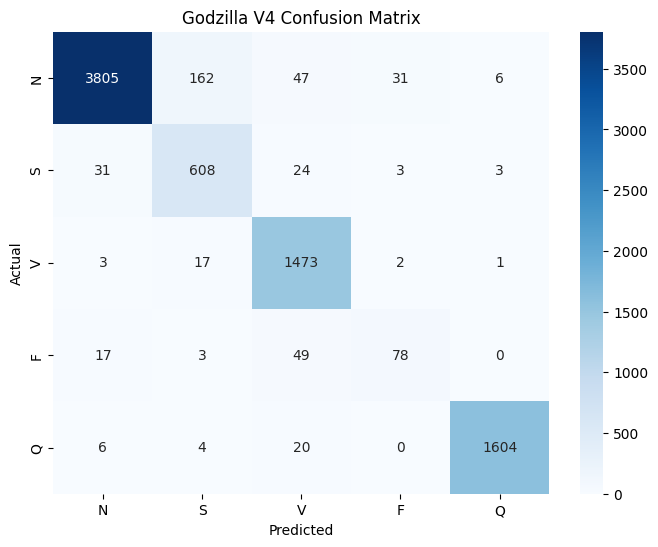


✅ Classification Report:
              precision    recall  f1-score   support

           N       0.99      0.94      0.96      4051
           S       0.77      0.91      0.83       669
           V       0.91      0.98      0.95      1496
           F       0.68      0.53      0.60       147
           Q       0.99      0.98      0.99      1634

    accuracy                           0.95      7997
   macro avg       0.87      0.87      0.87      7997
weighted avg       0.95      0.95      0.95      7997



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ==========================================
# GET PREDICTIONS
# ==========================================
y_true = []
y_pred = []

for i in range(len(val_gen)):
    x_batch, y_batch = val_gen[i]

    preds = model.predict(x_batch, verbose=0)

    y_true.extend(np.argmax(y_batch, axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# ==========================================
# METRICS
# ==========================================
acc = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred)

print(f"✅ Validation Accuracy: {acc*100:.2f}%")
print("\n✅ Confusion Matrix:")
print(cm)

# ==========================================
# PLOT MATRIX
# ==========================================
plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['N','S','V','F','Q'],
    yticklabels=['N','S','V','F','Q']
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Godzilla V4 Confusion Matrix")
plt.show()

# ==========================================
# REPORT
# ==========================================
print("\n✅ Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=['N','S','V','F','Q']
))

In [ ]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred)

results_df = pd.DataFrame({
    "Class": ['N','S','V','F','Q'],
    "Precision": np.round(precision, 3),
    "Recall": np.round(recall, 3),
    "F1-Score": np.round(f1, 3),
    "Support": support
})

print(results_df)

  Class  Precision  Recall  F1-Score  Support
0     N      0.985   0.939     0.962     4051
1     S      0.766   0.909     0.831      669
2     V      0.913   0.985     0.948     1496
3     F      0.684   0.531     0.598      147
4     Q      0.994   0.982     0.988     1634


In [ ]:
from sklearn.metrics import multilabel_confusion_matrix

mcm = multilabel_confusion_matrix(y_true, y_pred)

for i, label in enumerate(['N','S','V','F','Q']):
    tn, fp, fn, tp = mcm[i].ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    print(f"{label}: Sensitivity={sensitivity:.3f}, Specificity={specificity:.3f}")

N: Sensitivity=0.939, Specificity=0.986
S: Sensitivity=0.909, Specificity=0.975
V: Sensitivity=0.985, Specificity=0.978
F: Sensitivity=0.531, Specificity=0.995
Q: Sensitivity=0.982, Specificity=0.998


In [ ]:
# ==========================================
# 1. MOUNT & INITIALIZE
# ==========================================
from google.colab import drive
import os
import h5py
import numpy as np

# Mount Drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

# Path Setup
BASE_DIR = '/content/drive/MyDrive/Final_Year_Project/'
V4_2_PATH = os.path.join(BASE_DIR, 'datasets/v4.2_cleaned/v4.2_balanced.h5')

# ==========================================
# 2. REPLICATE THE SPLIT LOGIC
# ==========================================
with h5py.File(V4_2_PATH, 'r') as hf:
    labels = hf['labels'][:]  # Poore labels load karo verify karne ke liye
    total_samples = len(labels)

indices = np.arange(total_samples)

# Wahi Seed jo validation generator mein use kiya tha
np.random.seed(42)
np.random.shuffle(indices)

# 80/20 Split
split = int(0.8 * total_samples)
train_indices = indices[:split]
val_indices = indices[split:]

# Validation Labels nikalna
y_val_actual = labels[val_indices]

# ==========================================
# 3. THE ULTIMATE SANITY CHECK
# ==========================================
classes, counts = np.unique(y_val_actual, return_counts=True)

print("🔍 --- VALIDATION SET DISTRIBUTION CHECK ---")
print(f"Total Validation Samples: {len(y_val_actual)}")
print("-" * 45)

class_names = {0: 'N', 1: 'S', 2: 'V', 3: 'F', 4: 'Q'}

for cls, count in zip(classes, counts):
    percentage = (count / len(y_val_actual)) * 100
    print(f"Class {cls} ({class_names[cls]}): {count} samples ({percentage:.2f}%)")

# Final Verdict
if len(classes) == 5:
    print("\n✅ VERDICT: Saari 5 classes validation set mein maujood hain. Shuffling se data loss nahi hua!")
else:
    print(f"\n⚠️ WARNING: Sirf {len(classes)} classes mili hain. Kuch toh gadbad hai!")

Mounted at /content/drive
🔍 --- VALIDATION SET DISTRIBUTION CHECK ---
Total Validation Samples: 7997
---------------------------------------------
Class 0 (N): 4051 samples (50.66%)
Class 1 (S): 669 samples (8.37%)
Class 2 (V): 1496 samples (18.71%)
Class 3 (F): 147 samples (1.84%)
Class 4 (Q): 1634 samples (20.43%)

✅ VERDICT: Saari 5 classes validation set mein maujood hain. Shuffling se data loss nahi hua!


## Step 6. Grad-CAM (qualitative)
*Source: `v4_2_Model.ipynb`, cell 90.* Grad-CAM heatmaps computed from the trained model on the last
convolutional layer (`conv2d_2`), for one sample per class from the seed-42 subset above (all in the training
pool). This is a qualitative illustration only.

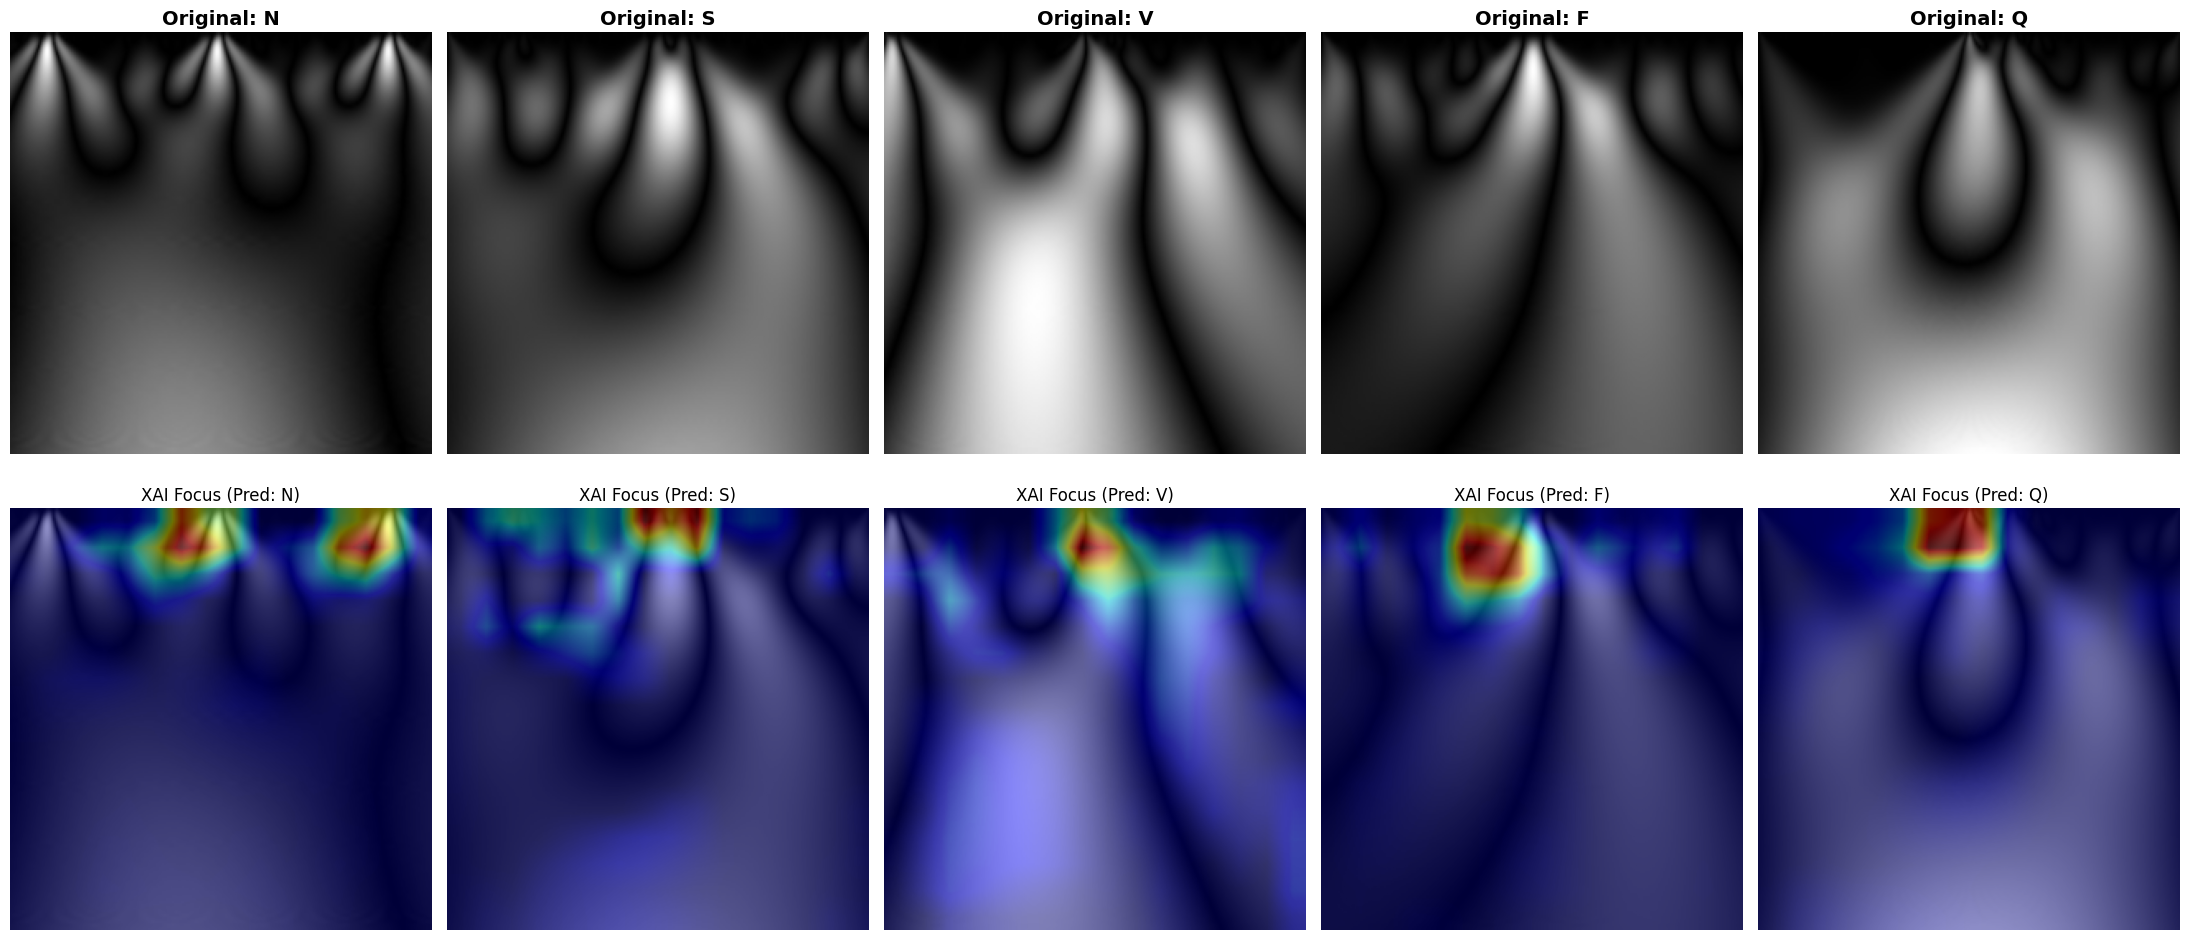

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import h5py

def get_gradcam_bypass(img_tensor, trained_model, target_layer_name):
    # 1. Sabse pehle input image ko trackable banayein
    img_tensor = tf.cast(img_tensor, tf.float32)

    with tf.GradientTape() as tape:
        # 2. Sequential model ki layers ko manually iterate karein
        # Taaki intermediate 'conv2d_2' output aur final prediction dono mil sakein
        activation = img_tensor
        target_activation = None

        for layer in trained_model.layers:
            activation = layer(activation)
            if layer.name == target_layer_name:
                target_activation = activation

        # 'activation' ab final prediction hai
        pred_index = tf.argmax(activation[0])
        class_channel = activation[:, pred_index]

    # 3. Gradients calculation w.r.t intermediate layer
    grads = tape.gradient(class_channel, target_activation)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # 4. Heatmap computation
    target_activation = target_activation[0]
    heatmap = target_activation @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # 5. ReLU & Normalization
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy(), pred_index.numpy()

# --- Visualization Loop for 5 Classes ---
class_names = ['N', 'S', 'V', 'F', 'Q']
fig, axes = plt.subplots(2, 5, figsize=(22, 10))

for i in range(5):
    try:
        # Sanity check wale indices se data uthana
        local_idx = np.where(y_val_actual == i)[0][0]
        global_idx = val_indices[local_idx]

        with h5py.File(V4_2_PATH, 'r') as hf:
            img = hf['images'][global_idx]

        # Godzilla Preprocessing (3 channels + 256x256)
        img_input = np.repeat(img[np.newaxis, ..., np.newaxis], 3, axis=-1) / 255.0
        img_input = tf.image.resize(img_input, (256, 256))

        # Use the Bypass Function
        heatmap, pred_idx = get_gradcam_bypass(img_input, model, "conv2d_2")

        # Display logic
        res_hm = tf.image.resize(heatmap[np.newaxis, ..., np.newaxis], (256, 256)).numpy()[0, ..., 0]
        display_img = img_input[0].numpy()

        axes[0, i].imshow(display_img)
        axes[0, i].set_title(f"Original: {class_names[i]}", fontsize=14, fontweight='bold')
        axes[0, i].axis('off')

        axes[1, i].imshow(display_img)
        axes[1, i].imshow(res_hm, cmap='jet', alpha=0.45)
        axes[1, i].set_title(f"XAI Focus (Pred: {class_names[pred_idx]})", fontsize=12)
        axes[1, i].axis('off')

    except Exception as e:
        print(f"❌ Error in Class {class_names[i]}: {e}")

plt.tight_layout()
plt.savefig('Godzilla_V4_XAI_Full.png', dpi=300)
plt.show()

## Excluded material

The original notebooks also contain material that is **not** part of this publication copy:

| Original cells | Reason |
|---|---|
| `v4_2_Model` 69, 70 | **Synthetic figures.** A Grad-CAM drawn on a synthetic beat with a hand-made heatmap, and a hard-coded "AAMI difference matrix". |
| `v4_2_Model` 87, 88, 89 | **Synthetic training curves** generated from formulas, not from training history. |
| `v4_2_Model` 84 | Re-plots the synthetic curves of cells 88/89, plus ROC/PR curves over all samples. |
| `v4_2_Model` 65–68, 85, 86 | ROC/PR curves, confusion matrices and a report computed over **all 39,982 samples**, i.e. including training data (accuracy 94.43%). Omitted as misleading. |
| `v4_2_Model` 14–16, 21, 62 | Other architectures (a 26M-parameter CNN, a single-channel CNN, a 4-class stub) that are not the deployed model. |
| `v4_2_Model` 93–104 | Colab Gradio demos (with now-expired public share links). Replaced by `app/` in this repository. |
| `v4_Preprocessing` 0–20 | Drive maintenance, an earlier resume copy of the step-1 generator (cell 2), an unused 187-sample `.npy` extraction, and an unused jet-colormap RGB scalogram engine (cell 6). |

## Reproducibility status

- **Verified:** preprocessing parity (see step 1); the deployed checkpoint matches step 4; class order N, S, V, F, Q.
- **Not reproducible from this repository alone:** the raw records, batch files and balanced dataset are not distributed.
- **Not available:** a patient/record-wise evaluation. The record split of step 1 is recoverable from the batch
  files, but the deployed model was trained after that split was merged away (step 3), so a fair patient-wise test
  would require retraining.